In [1]:
import os
import sys
import json
from pathlib import Path


In [2]:
PROJECT_ROOT = Path(os.environ.get("SAFETY_WATCH_PROJECT_ROOT", "/workspace"))
RUNTIME_ROOT = Path(os.environ.get("SAFETY_WATCH_RUNTIME_ROOT", "/runtime"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from safety_watch.canary import train_canary, export_canary, load_pair, evaluate_pair
from safety_watch.classifier.runtime import check_runtime


In [4]:
print(json.dumps(check_runtime(), indent=2))


{
  "python": "3.12.15",
  "architecture": "s390x",
  "interpreter": "/opt/venv/bin/python3",
  "sklearn": "1.9.0",
  "numpy": "2.0.2",
  "scipy": "1.13.1",
  "pandas": "3.0.6",
  "joblib": "1.6.0"
}


In [5]:
TRAIN_NEW_MODEL = False
FREEZE_CANARY = False
MODEL_DIR = RUNTIME_ROOT / "models"


In [6]:
SOURCE_RUN = RUNTIME_ROOT / (
    "results/classifier-runs/canary-train-20261017T090644Z-6cfe5d16"
)


In [7]:
if TRAIN_NEW_MODEL:
    trained = train_canary(RUNTIME_ROOT, PROJECT_ROOT)
    SOURCE_RUN = trained.run_dir


In [8]:
card = json.loads((SOURCE_RUN / "model-card.json").read_text())
summary = json.loads((SOURCE_RUN / "run-summary.json").read_text())
print("Source run:", card["run_id"])


Source run: 20261017T090644Z-6cfe5d16


In [9]:
print(json.dumps(card["configuration"]["model"], indent=2))


{
  "C": 3.0,
  "analyzer": "word",
  "class_weight": "balanced",
  "lowercase": true,
  "max_features": 100000,
  "max_iter": 1000,
  "min_df": 2,
  "ngram_range": [
    1,
    2
  ],
  "norm": "l2",
  "solver": "liblinear",
  "sublinear_tf": true
}


In [10]:
print(json.dumps(card["model_selection"], indent=2))


{
  "candidate_count": 12,
  "classifier_fits": 36,
  "enabled": true,
  "folds": 3,
  "ranking": "pooled human recall at <=5% fold FPR, then mean AP, smaller C, no weighting",
  "scope": "fitting partition only",
  "search_artifact_sha256": "05bc79b99e6b324def9f46bc16d3ac521377deccf5d531ad96fd742b7a6cc50c",
  "search_seconds": 1.1139336600026581,
  "selected_cv_average_precision": 0.6731058329046649,
  "selected_cv_recall": 0.631768953068592,
  "selected_parameters": {
    "C": 3.0,
    "class_weight": "balanced"
  }
}


In [11]:
print(json.dumps(card["threshold"], indent=2))


{
  "benign_human_refused": 22,
  "benign_human_validation_records": 457,
  "decision": "score >= threshold (diagnostic only)",
  "observed_fpr": 0.04814004376367615,
  "target_fpr": 0.05,
  "threshold": 0.5656831460118261
}


In [12]:
print(pd.DataFrame(card["validation_metrics"]).T.to_string())


                               average_precision  benign        f1  false_negative_rate    fn    fp       fpr  precision    recall  records     tn    tp  unsafe
full_validation_supplementary           0.717168   889.0  0.657895             0.285714  20.0  32.0  0.035996   0.609756  0.714286    959.0  857.0  50.0    70.0
human_annotated                         0.756148   457.0  0.704225             0.285714  20.0  22.0  0.048140   0.694444  0.714286    527.0  435.0  50.0    70.0


In [13]:
print(json.dumps(card["runtime"], indent=2))


{
  "feature_count": 16002,
  "model_bytes": 752048,
  "process_peak_rss_mib": 218.34765625,
  "solver_iterations": [
    6
  ],
  "training_seconds": 0.21851512799912598
}


In [14]:
if FREEZE_CANARY:
    print(json.dumps(export_canary(SOURCE_RUN, RUNTIME_ROOT), indent=2))
else:
    print("Canary export disabled; using the verified saved pair.")


Canary export disabled; using the verified saved pair.


In [15]:
guardrail, canary = load_pair(MODEL_DIR)
published_guardrail, published_canary = load_pair(PROJECT_ROOT / "models")
assert published_guardrail.digest == guardrail.digest
assert published_canary.digest == canary.digest


In [16]:
pair_report = evaluate_pair(RUNTIME_ROOT, MODEL_DIR)
print("Verified paired records: 959")
print("Saved-pair reload smoke records:", pair_report["reload_smoke_records"])


Verified paired records: 959
Saved-pair reload smoke records: 100


In [17]:
human_metrics = {
    name: report["human_annotated"]
    for name, report in pair_report["metrics"].items()
}
print(pd.DataFrame(human_metrics).T.to_string())


           records  benign  unsafe     tn    fp    fn    tp  precision    recall        f1      fpr  false_negative_rate  average_precision
guardrail    527.0   457.0    70.0  435.0  22.0  18.0  52.0   0.702703  0.742857  0.722222  0.04814             0.257143           0.788108
canary       527.0   457.0    70.0  435.0  22.0  20.0  50.0   0.694444  0.714286  0.704225  0.04814             0.285714           0.756148


In [18]:
print(json.dumps(pair_report["error_correlation"]["human_annotated"], indent=2))


{
  "records": 527,
  "error_indicator_pearson_phi": 0.7622478434108937,
  "both_wrong": 32,
  "guardrail_only_wrong": 8,
  "canary_only_wrong": 10,
  "both_correct": 477,
  "prediction_disagreement": 18,
  "prediction_disagreement_rate": 0.03415559772296015,
  "unsafe_records": 70,
  "shared_unsafe_misses": 16,
  "guardrail_misses_canary_flags": 2,
  "canary_misses_guardrail_flags": 4
}


In [19]:
score_path = Path(pair_report["results_directory"]) / "joint-validation-scores.jsonl"
scores = pd.read_json(score_path, lines=True)
disagreement = scores["guardrail_score"] - scores["canary_score"]


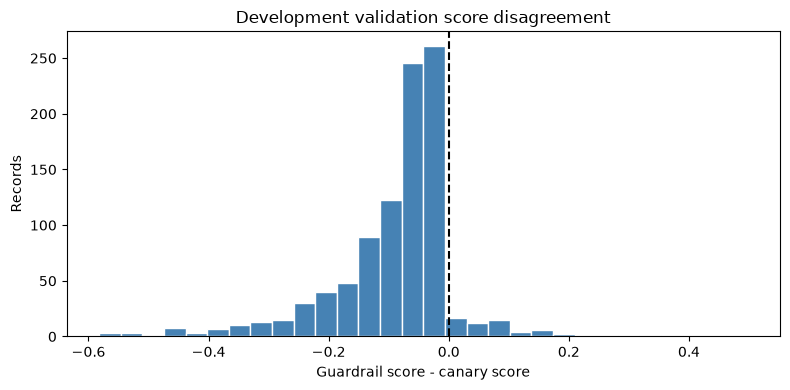

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(disagreement, bins=30, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", linestyle="--")
ax.set(
    xlabel="Guardrail score - canary score",
    ylabel="Records",
    title="Development validation score disagreement",
)
fig.tight_layout()
plt.show()
plt.close(fig)


In [21]:
print(json.dumps(pair_report["reference"], indent=2))


{
  "records": 457,
  "path": "/runtime/results/classifier-runs/pair-evaluate-20261017T090949Z-81df8964/benign-reference-scores.jsonl",
  "sha256": "ae2f76aace62a35c5a81cef313c4ff4a45705eb04c8d7071663cce573f8926b9",
  "scope": "Human-benign validation; also threshold calibration, not independent null calibration."
}


In [22]:
print(json.dumps({
    "guardrail_sha256": guardrail.digest,
    "canary_sha256": canary.digest,
    "thresholds": pair_report["thresholds"],
    "evidence": pair_report["evidence"],
}, indent=2))


{
  "guardrail_sha256": "16cc50b1e16df16f937cc89c64eea164ed59f70275ccad09cc9303af1e9f2fce",
  "canary_sha256": "617667b90a430ff08be9fabf9a014b5fd37a6c0c05937b2b374eea6a31a81c8d",
  "thresholds": {
    "guardrail": 0.3590141404799981,
    "canary": 0.5656831460118261
  },
  "evidence": {
    "records": 4,
    "head": "006de078fe0247ba4933285ba6dfcdd96325941ec1727a888d4b94b80ebe9f0c"
  }
}
